### Exercise 1

Make an application which is capable of translating RNA molecules into proteins, using the genetic code table.
Translation starts at the first start codon (AUG) and ends at the first stop codon (UAA, UAG, UGA).
Input: S = GCAUGGCCAUUGUAAUGGGCCGCUGAAAGGGUGCCCGAUAG

In [2]:

start_Codon = "AUG"
stop_Codon = ["UAA", "UAG", "UGA"]

GENETIC_CODE = {
    "UUU": "F", "UUC": "F", "UUA": "L", "UUG": "L",
    "UCU": "S", "UCC": "S", "UCA": "S", "UCG": "S",
    "UAU": "Y", "UAC": "Y", "UAA": "*", "UAG": "*",
    "UGU": "C", "UGC": "C", "UGA": "*", "UGG": "W",

    "CUU": "L", "CUC": "L", "CUA": "L", "CUG": "L",
    "CCU": "P", "CCC": "P", "CCA": "P", "CCG": "P",
    "CAU": "H", "CAC": "H", "CAA": "Q", "CAG": "Q",
    "CGU": "R", "CGC": "R", "CGA": "R", "CGG": "R",

    "AUU": "I", "AUC": "I", "AUA": "I", "AUG": "M",
    "ACU": "T", "ACC": "T", "ACA": "T", "ACG": "T",
    "AAU": "N", "AAC": "N", "AAA": "K", "AAG": "K",
    "AGU": "S", "AGC": "S", "AGA": "R", "AGG": "R",

    "GUU": "V", "GUC": "V", "GUA": "V", "GUG": "V",
    "GCU": "A", "GCC": "A", "GCA": "A", "GCG": "A",
    "GAU": "D", "GAC": "D", "GAA": "E", "GAG": "E",
    "GGU": "G", "GGC": "G", "GGA": "G", "GGG": "G",
}

AMINO_ACID_NAMES = {
    "A": "Ala", "R": "Arg", "N": "Asn", "D": "Asp", "C": "Cys",
    "Q": "Gln", "E": "Glu", "G": "Gly", "H": "His", "I": "Ile",
    "L": "Leu", "K": "Lys", "M": "Met", "F": "Phe", "P": "Pro",
    "S": "Ser", "T": "Thr", "W": "Trp", "Y": "Tyr", "V": "Val",
    "*": "Stop",
}


def RNA_Translation(Rna):
    if not set(Rna).issubset("ACGU"):
        print("invalid nucleotides")
        return
    start = Rna.find(start_Codon)
    if start == -1:
        print("No start codon (AUG) found")
        return

    codons, protein = [], []
    for i in range(start,len(Rna), 3):
        codon = Rna[i:i+3]
        codons.append(codon)
        amino_acid = GENETIC_CODE[codon]
        if amino_acid == "*": #stop
            break
        protein.append(amino_acid)
    return start, codons, "".join(protein)

    

S = "GCAUGGCCAUUGUAAUGGGCCGCUGAAAGGGUGCCCGAUAG"
start, codons, protein = RNA_Translation(S)
print(f"mRNA: {S}")

print("\nCodon -> amino acid:")
for codon in codons:
    am = GENETIC_CODE[codon]
    print(f"{codon} -> {AMINO_ACID_NAMES[am]:4} ({am})")
print()
print(f"Protein: {protein}")
print(f"         {'-'.join(AMINO_ACID_NAMES[aa] for aa in protein)}")

mRNA: GCAUGGCCAUUGUAAUGGGCCGCUGAAAGGGUGCCCGAUAG

Codon -> amino acid:
AUG -> Met  (M)
GCC -> Ala  (A)
AUU -> Ile  (I)
GUA -> Val  (V)
AUG -> Met  (M)
GGC -> Gly  (G)
CGC -> Arg  (R)
UGA -> Stop (*)

Protein: MAIVMGR
         Met-Ala-Ile-Val-Met-Gly-Arg


### Exercise 2

Download from NCBI a viral or bacterial genome as a FASTA file (here: *Escherichia coli* str. K-12 substr. MG1655, NC_000913.3).
Make an application which is able to scan the entire genome using a sliding window of 3 positions (letters), and measure the frequency of each codon.
There are 64 codons in total; show the top 10 codons with the highest frequency and make a chart of their frequencies.

Genome: Escherichia coli str. K-12 substr. MG1655 (NC_000913.3)
Length = 4,641,652 nucleotides
Windows scanned = 4,641,650, distinct codons = 64 / 64

Top 10 codons:
 1. CGC (Arg)  115,734  ->  2.49%
 2. GCG (Ala)  114,670  ->  2.47%
 3. TTT (Phe)  109,862  ->  2.37%
 4. AAA (Lys)  108,964  ->  2.35%
 5. CAG (Gln)  104,850  ->  2.26%
 6. CTG (Leu)  102,957  ->  2.22%
 7. GCA (Ala)   96,071  ->  2.07%
 8. TGC (Cys)   95,270  ->  2.05%
 9. GCC (Ala)   93,028  ->  2.00%
10. GGC (Gly)   92,189  ->  1.99%


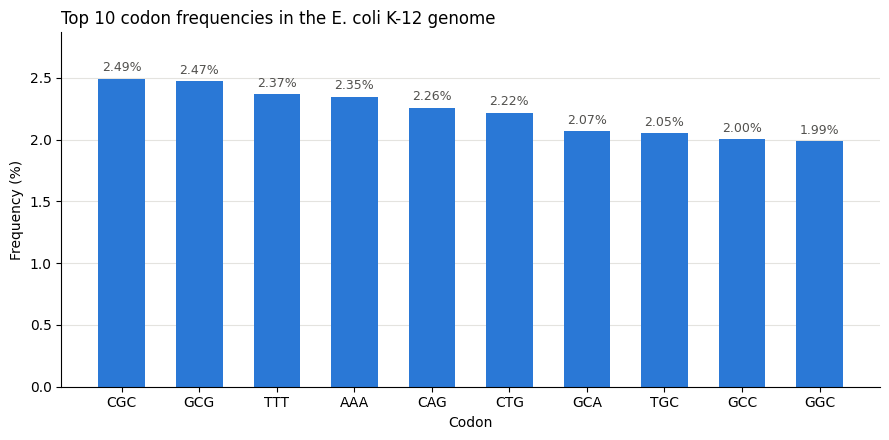

In [3]:
from collections import Counter
from itertools import product
import matplotlib.pyplot as plt

def codon_frequencies(seq):
    counts = Counter(seq[i:i + 3] for i in range(len(seq) - 3 + 1))
    all_codons = ["".join(c) for c in product("ACGT", repeat=3)]
    return {codon: counts[codon] for codon in all_codons}

with open("ecoli_K12_MG1655.fasta") as f:
    genome =  "".join(line.strip() for line in f if not line.startswith(">")).upper()

counts = codon_frequencies(genome)
total = sum(counts.values())
top10 = sorted(counts.items(), key=lambda item: item[1], reverse=True)[:10]

print("Genome: Escherichia coli str. K-12 substr. MG1655 (NC_000913.3)")
print(f"Length = {len(genome):,} nucleotides")
print(f"Windows scanned = {total:,}, distinct codons = {sum(1 for c in counts.values() if c)} / 64")
print()
print("Top 10 codons:")
for rank, (codon, count) in enumerate(top10, 1):
    aa = GENETIC_CODE[codon.replace("T", "U")]
    print(f"{rank:2d}. {codon} ({AMINO_ACID_NAMES[aa]})  {count:7,d}  ->  {100 * count / total:.2f}%")

codons = [codon for codon, _ in top10]
percents = [100 * count / total for _, count in top10]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(codons, percents, width=0.6, color="#2a78d6")
ax.bar_label(bars, labels=[f"{p:.2f}%" for p in percents], padding=3, fontsize=9, color="#52514e")
ax.set_title("Top 10 codon frequencies in the E. coli K-12 genome", loc="left", fontsize=12)
ax.set_xlabel("Codon")
ax.set_ylabel("Frequency (%)")
ax.set_ylim(0, max(percents) * 1.15)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Exercise 3

Analyze the top 10 most frequent codons of the bacterium: find which amino acids they encode,
and based on them recommend what to eat (foods to limit, which are rich in those amino acids, and foods that are low in them).

In [4]:
# 1. Map each amino acid to common foods rich in it
FOODS_RICH_IN = {
    "A": ["meat", "poultry", "fish", "eggs"],
    "R": ["nuts", "seeds", "dairy", "meat"],
    "N": ["dairy", "beef", "poultry", "eggs"],
    "D": ["poultry", "beef", "dairy", "sprouts"],
    "C": ["eggs", "meat", "red peppers", "garlic"],
    "Q": ["meat", "fish", "eggs", "dairy"],
    "E": ["cheese", "meat", "fish", "mushrooms"],
    "G": ["meat", "fish", "dairy", "beans"],
    "H": ["meat", "fish", "dairy", "grains"],
    "I": ["meat", "fish", "eggs", "lentils"],
    "L": ["meat", "dairy", "soy", "beans"],
    "K": ["meat", "poultry", "fish", "cheese"],
    "M": ["eggs", "fish", "meat", "garlic"],
    "F": ["dairy", "meat", "poultry", "fish"],
    "P": ["meat", "dairy", "eggs"],
    "S": ["soy", "eggs", "dairy", "meat"],
    "T": ["cottage cheese", "poultry", "fish", "meat"],
    "W": ["turkey", "dairy", "oats", "nuts"],
    "Y": ["cheese", "soy", "meat", "fish"],
    "V": ["cheese", "meat", "mushrooms", "peanuts"]
}

# Foods naturally low in protein/amino acids
LOW_PROTEIN_FOODS = [
    "Fruits (apples, berries, oranges)",
    "Leafy green vegetables and cucumbers",
    "Tomatoes, carrots, and celery",
    "Olive oil and vegetable fats"
]

# 2. Count the frequency of each amino acid encoded by the top 10 codons
aa_counts = {}
for codon, count in top10:
    aa = GENETIC_CODE[codon.replace("T", "U")]
    aa_counts[aa] = aa_counts.get(aa, 0) + count

print("Amino acids encoded by the top 10 codons:")
for aa, count in sorted(aa_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"- {AMINO_ACID_NAMES[aa]} ({aa}): {count:,} times")

# 3. Recommendations
print("\n--- Food Recommendations ---")
print("Foods to LIMIT (rich in the amino acids E. coli uses most):")
foods_to_limit = set()
for aa in aa_counts:
    foods_to_limit.update(FOODS_RICH_IN.get(aa, []))
for food in sorted(foods_to_limit):
    print(f"  [!] {food}")

print("\nFoods to EAT (naturally low in these amino acids):")
for food in LOW_PROTEIN_FOODS:
    print(f"  [+] {food}")


Amino acids encoded by the top 10 codons:
- Ala (A): 303,769 times
- Arg (R): 115,734 times
- Phe (F): 109,862 times
- Lys (K): 108,964 times
- Gln (Q): 104,850 times
- Leu (L): 102,957 times
- Cys (C): 95,270 times
- Gly (G): 92,189 times

--- Food Recommendations ---
Foods to LIMIT (rich in the amino acids E. coli uses most):
  [!] beans
  [!] cheese
  [!] dairy
  [!] eggs
  [!] fish
  [!] garlic
  [!] meat
  [!] nuts
  [!] poultry
  [!] red peppers
  [!] seeds
  [!] soy

Foods to EAT (naturally low in these amino acids):
  [+] Fruits (apples, berries, oranges)
  [+] Leafy green vegetables and cucumbers
  [+] Tomatoes, carrots, and celery
  [+] Olive oil and vegetable fats
